# EEG Deception Classification Results

This notebook presents the completed non-subject-wise experiment for four behavioral classes: **Honest, Bluffer, Liar, and Deceiver**. The stored experiment used MinMax scaling and trial-grouped 10-fold cross-validation, so all windows from a trial remained in one fold. Participants were allowed to occur in both the training and test portions of a fold. Trial-level performance is therefore the primary result, and the findings describe within-dataset discrimination rather than generalization to unseen participants.

> **Scope:** Every value and existing figure below is loaded from `outputs/minmax_10fold_trial_grouped/`. No preprocessing, feature extraction, model fitting, cross-validation, or evaluation pipeline is run in this notebook.

# 1. Terminology

- **Session:** One mock-crime data-collection session involving a group of participants.
- **Participant or subject:** A person whose EEG was recorded during a session.
- **Role or class:** The behavioral label assigned to a trial: Honest, Bluffer, Liar, or Deceiver.
- **Question:** The prompt associated with an EEG trial.
- **Trial:** One participant-role-question observation and its associated EEG recording.
- **Thinking epoch:** The five-second EEG interval used for analysis before the response.
- **Window:** A one-second segment extracted from the thinking epoch; adjacent windows overlap by 50%.
- **Feature vector:** The channel-wise time- and frequency-domain measurements representing one window.
- **Fold:** One train/test partition in the 10-fold procedure.
- **Out-of-fold prediction:** A prediction made for an observation only when its trial was held out from model fitting.
- **Window-level prediction:** A class prediction for one EEG window.
- **Trial-level prediction:** A class prediction obtained by aggregating the stored probabilities across all windows from a trial.
- **Pooled out-of-fold metric:** A metric calculated after combining predictions from all 10 held-out folds.
- **Mean metric across folds:** The arithmetic mean of the metric calculated separately in each fold.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, Markdown, display

pd.set_option("display.float_format", lambda value: f"{value:.4f}")
plt.rcParams.update({"figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.25})

NOTEBOOK_PATH = Path("EEG Deception Results.ipynb")
RESULT_DIR = Path("outputs") / "minmax_10fold_trial_grouped"
CLASS_ORDER = ["Honest", "Bluffer", "Liar", "Deceiver"]
MODEL_DISPLAY = {
    "logistic_regression": "Logistic Regression",
    "decision_tree": "Decision Tree",
    "random_forest": "Random Forest",
    "xgboost": "XGBoost",
    "svm": "SVM",
    "knn": "KNN",
    "naive_bayes": "Gaussian Naive Bayes",
    "mlp": "MLP",
}

CSV_FILES = {
    "model_comparison": "model_comparison.csv",
    "fold_metrics": "fold_metrics.csv",
    "pooled_window_metrics": "pooled_window_metrics.csv",
    "pooled_trial_metrics": "pooled_trial_metrics.csv",
    "per_class_trial_metrics": "per_class_trial_metrics.csv",
    "oof_window_predictions": "oof_window_predictions.csv",
    "oof_trial_predictions": "oof_trial_predictions.csv",
    "fold_participant_overlap": "fold_participant_overlap.csv",
}
EXPECTED_FILES = list(CSV_FILES.values()) + [
    "experiment_summary.txt",
    "experiment_manifest.json",
    "model_comparison.png",
] + [f"confusion_matrix_{model}.png" for model in MODEL_DISPLAY]

if not RESULT_DIR.is_dir():
    raise FileNotFoundError(f"Stored results directory not found: {RESULT_DIR.as_posix()}")

results = {
    key: pd.read_csv(RESULT_DIR / filename) if (RESULT_DIR / filename).is_file() else pd.DataFrame()
    for key, filename in CSV_FILES.items()
}
manifest_path = RESULT_DIR / "experiment_manifest.json"
manifest = json.loads(manifest_path.read_text(encoding="utf-8")) if manifest_path.is_file() else {}
summary_path = RESULT_DIR / "experiment_summary.txt"
summary_text = summary_path.read_text(encoding="utf-8", errors="replace") if summary_path.is_file() else ""
missing_files = [name for name in EXPECTED_FILES if not (RESULT_DIR / name).is_file()]

TABLES_DISPLAYED = 0
FIGURES_DISPLAYED = 0

def show_table(frame: pd.DataFrame, *, highlight_first_row: bool = False) -> None:
    """Display a compact paper-style copy while preserving the source DataFrame."""
    global TABLES_DISPLAYED
    view = frame.copy()
    numeric_columns = view.select_dtypes(include="number").columns
    view.loc[:, numeric_columns] = view.loc[:, numeric_columns].round(4)
    if highlight_first_row and not view.empty:
        style = view.style.apply(
            lambda row: ["background-color: #d9ead3; font-weight: bold" if row.name == view.index[0] else "" for _ in row],
            axis=1,
        ).format(precision=4, na_rep="—").hide(axis="index")
        display(style)
    else:
        display(view)
    TABLES_DISPLAYED += 1

def show_existing_figure(path: Path, *, width: int = 900) -> bool:
    """Embed an existing PNG and count it; report a missing image without recreating it."""
    global FIGURES_DISPLAYED
    if path.is_file():
        display(Image(filename=str(path), width=width))
        FIGURES_DISPLAYED += 1
        return True
    display(Markdown(f"> **Missing figure:** `{path.as_posix()}`"))
    return False

if missing_files:
    display(Markdown("> **Missing stored artifacts:** " + ", ".join(f"`{name}`" for name in missing_files)))

# 2. Experiment Summary

The following excerpt and tables are read from the stored experiment summary, manifest, overlap audit, and out-of-fold result files.

In [2]:
if summary_text:
    summary_prefixes = (
        "MINMAX", "Feature-matrix", "Unique trials", "Unique participants", "Unique sessions",
        "Window class distribution", "Splitter", "Trial overlap", "Average overlapping participants",
        "Best model", "Pooled trial", "Best-model trial",
    )
    selected_lines = [
        line.replace("Â±", "±")
        for line in summary_text.splitlines()
        if line.startswith(summary_prefixes)
    ]
    display(Markdown("```text\n" + "\n".join(selected_lines) + "\n```"))
else:
    display(Markdown("> **Missing file:** `outputs/minmax_10fold_trial_grouped/experiment_summary.txt`"))

feature_summary = manifest.get("feature_summary", {})
splitter = manifest.get("splitter", {})
overlap = results["fold_participant_overlap"]
comparison = results["model_comparison"]
model_names = [MODEL_DISPLAY.get(name, name) for name in comparison.get("model", pd.Series(dtype=str)).tolist()]

trial_overlap_max = overlap["trial_overlap_count"].max() if "trial_overlap_count" in overlap else None
participant_overlap_mean = overlap["n_overlapping_participants"].mean() if "n_overlapping_participants" in overlap else None
participant_overlap_pct = 100 * overlap["participant_overlap_fraction_of_test"].mean() if "participant_overlap_fraction_of_test" in overlap else None
experiment_overview = pd.DataFrame(
    [
        ("Windows", feature_summary.get("row_count")),
        ("Trials", feature_summary.get("trial_count")),
        ("Participants", feature_summary.get("participant_count")),
        ("Sessions", feature_summary.get("session_count")),
        ("EEG features per window", feature_summary.get("feature_count")),
        ("Windows per trial", feature_summary.get("windows_per_trial", {}).get("minimum")),
        ("Cross-validation", f"{splitter.get('class', 'Unavailable')} ({splitter.get('n_splits', '—')} folds)"),
        ("Grouping unit", splitter.get("group", "Unavailable")),
        ("Scaler and imputation", manifest.get("scaling", "Unavailable")),
        ("Models", ", ".join(model_names)),
        ("Maximum trial overlap across folds", trial_overlap_max),
        ("Mean overlapping participants per fold", participant_overlap_mean),
        ("Mean test-participant overlap", f"{participant_overlap_pct:.1f}%" if participant_overlap_pct is not None else "Unavailable"),
    ],
    columns=["Item", "Stored value"],
)
show_table(experiment_overview)

window_distribution = feature_summary.get("window_class_distribution_external_labels", {})
trial_distribution = feature_summary.get("trial_class_distribution_external_labels", {})
class_distribution = pd.DataFrame(
    {
        "Role ID": [1, 2, 3, 4],
        "Class": CLASS_ORDER,
        "Windows": [window_distribution.get(str(index)) for index in range(1, 5)],
        "Trials": [trial_distribution.get(str(index)) for index in range(1, 5)],
    }
)
show_table(class_distribution)

```text
MINMAX 10-FOLD TRIAL-GROUPED EXPERIMENT SUMMARY
Feature-matrix shape: (7200, 496)
Unique trials: 800
Unique participants: 48
Unique sessions: 17
Window class distribution (external labels): {'1': 1737, '2': 1899, '3': 1755, '4': 1809}
Splitter: StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=42)
Trial overlap in every fold: 0
Average overlapping participants/fold: 45.20
Best model by pooled trial macro F1: xgboost
Pooled trial accuracy: 0.968750
Pooled trial macro F1: 0.968523
Pooled trial weighted F1: 0.968748
Pooled trial Cohen's kappa: 0.958317
Best-model trial fold accuracy mean ± std: 0.968750 ± 0.021449
Best-model trial fold macro F1 mean ± std: 0.967824 ± 0.022719
Best-model trial fold weighted F1 mean ± std: 0.968820 ± 0.021284
Best-model trial fold kappa mean ± std: 0.958152 ± 0.028753
```

,Item,Stored value
0,Windows,7200
1,Trials,800
2,Participants,48
3,Sessions,17
4,EEG features per window,496
5,Windows per trial,9
6,Cross-validation,StratifiedGroupKFold (10 folds)
7,Grouping unit,trial_id
8,Scaler and imputation,"SimpleImputer(median) then MinMaxScaler(0,1), ..."
9,Models,"XGBoost, Random Forest, Decision Tree, MLP, KN..."


,Role ID,Class,Windows,Trials
0,1,Honest,1737,193
1,2,Bluffer,1899,211
2,3,Liar,1755,195
3,4,Deceiver,1809,201


# 3. Main Trial-Level Model Comparison

Models are ranked by the stored pooled trial-level macro F1-score. The highlighted row is the primary best model.

In [3]:
trial_columns = {
    "model": "Model",
    "pooled_trial_accuracy": "Pooled Accuracy",
    "pooled_trial_macro_precision": "Pooled Macro Precision",
    "pooled_trial_macro_recall": "Pooled Macro Recall",
    "pooled_trial_macro_f1": "Pooled Macro F1",
    "pooled_trial_weighted_f1": "Pooled Weighted F1",
    "pooled_trial_cohen_kappa": "Cohen's Kappa",
    "trial_fold_accuracy_mean": "Mean Fold Accuracy",
    "trial_fold_accuracy_std": "SD Fold Accuracy",
    "trial_fold_macro_f1_mean": "Mean Fold Macro F1",
    "trial_fold_macro_f1_std": "SD Fold Macro F1",
    "trial_fold_cohen_kappa_mean": "Mean Fold Kappa",
    "trial_fold_cohen_kappa_std": "SD Fold Kappa",
}
main_trial_table = comparison.loc[:, list(trial_columns)].rename(columns=trial_columns).copy()
main_trial_table["Model"] = main_trial_table["Model"].map(lambda name: MODEL_DISPLAY.get(name, name))
main_trial_table = main_trial_table.sort_values("Pooled Macro F1", ascending=False).reset_index(drop=True)
show_table(main_trial_table, highlight_first_row=True)

Model,Pooled Accuracy,Pooled Macro Precision,Pooled Macro Recall,Pooled Macro F1,Pooled Weighted F1,Cohen's Kappa,Mean Fold Accuracy,SD Fold Accuracy,Mean Fold Macro F1,SD Fold Macro F1,Mean Fold Kappa,SD Fold Kappa
XGBoost,0.9688,0.9685,0.9685,0.9685,0.9687,0.9583,0.9688,0.0214,0.9678,0.0227,0.9582,0.0288
Random Forest,0.9575,0.9571,0.9571,0.9571,0.9575,0.9433,0.9575,0.0158,0.9563,0.0169,0.9431,0.0212
Decision Tree,0.9275,0.9274,0.9272,0.9272,0.9277,0.9033,0.9275,0.0357,0.9265,0.0358,0.9029,0.0479
MLP,0.9150,0.9140,0.9144,0.9141,0.9147,0.8866,0.9150,0.0327,0.9115,0.0359,0.8863,0.0437
KNN,0.8712,0.8752,0.8706,0.8723,0.8728,0.8282,0.8712,0.0373,0.8703,0.0387,0.8280,0.0495
Logistic Regression,0.8138,0.8197,0.8140,0.8155,0.8160,0.7517,0.8138,0.0124,0.8123,0.0137,0.7508,0.0168
SVM,0.7900,0.7995,0.7902,0.7931,0.7935,0.7200,0.7900,0.0275,0.7909,0.0265,0.7195,0.0367
Gaussian Naive Bayes,0.3425,0.4560,0.3488,0.2910,0.2900,0.1305,0.3425,0.0374,0.2891,0.0517,0.1306,0.0443


# 4. Window-Level Results

These pooled out-of-fold window metrics are secondary. Multiple overlapping windows originate from each trial and are therefore correlated, although all windows from a trial remained in the same fold.

In [4]:
window_metrics = results["pooled_window_metrics"].copy()
window_columns = {
    "model": "Model",
    "n_samples": "Windows",
    "accuracy": "Accuracy",
    "macro_precision": "Macro Precision",
    "macro_recall": "Macro Recall",
    "macro_f1": "Macro F1",
    "weighted_f1": "Weighted F1",
    "cohen_kappa": "Cohen's Kappa",
}
window_table = window_metrics.loc[:, list(window_columns)].rename(columns=window_columns)
window_table["Model"] = window_table["Model"].map(lambda name: MODEL_DISPLAY.get(name, name))
window_table = window_table.sort_values("Macro F1", ascending=False).reset_index(drop=True)
show_table(window_table)

,Model,Windows,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Cohen's Kappa
0,XGBoost,7200,0.9562,0.9560,0.9559,0.9559,0.9563,0.9416
1,Random Forest,7200,0.9379,0.9372,0.9374,0.9373,0.9378,0.9172
2,Decision Tree,7200,0.8792,0.8793,0.8786,0.8789,0.8793,0.8388
3,MLP,7200,0.8600,0.8601,0.8594,0.8597,0.8603,0.8133
4,KNN,7200,0.7564,0.7589,0.7553,0.7566,0.7571,0.6749
5,Logistic Regression,7200,0.7329,0.7333,0.7326,0.7327,0.7333,0.6438
6,SVM,7200,0.7275,0.7414,0.7277,0.7308,0.7314,0.6367
7,Gaussian Naive Bayes,7200,0.3407,0.4514,0.3468,0.2893,0.2885,0.1281


# 5. Best Model Summary

The best model is selected exclusively by the stored pooled **trial-level macro F1-score**.

In [5]:
best_row = comparison.sort_values("pooled_trial_macro_f1", ascending=False).iloc[0]
best_model = best_row["model"]
best_model_name = MODEL_DISPLAY.get(best_model, best_model)
best_summary = pd.DataFrame(
    [
        {
            "Model": best_model_name,
            "Pooled Accuracy": best_row["pooled_trial_accuracy"],
            "Pooled Macro Precision": best_row["pooled_trial_macro_precision"],
            "Pooled Macro Recall": best_row["pooled_trial_macro_recall"],
            "Pooled Macro F1": best_row["pooled_trial_macro_f1"],
            "Pooled Weighted F1": best_row["pooled_trial_weighted_f1"],
            "Cohen's Kappa": best_row["pooled_trial_cohen_kappa"],
            "Fold Accuracy (mean ± SD)": f"{best_row['trial_fold_accuracy_mean']:.4f} ± {best_row['trial_fold_accuracy_std']:.4f}",
            "Fold Macro F1 (mean ± SD)": f"{best_row['trial_fold_macro_f1_mean']:.4f} ± {best_row['trial_fold_macro_f1_std']:.4f}",
            "Fold Kappa (mean ± SD)": f"{best_row['trial_fold_cohen_kappa_mean']:.4f} ± {best_row['trial_fold_cohen_kappa_std']:.4f}",
        }
    ]
)
show_table(best_summary)

,Model,Pooled Accuracy,Pooled Macro Precision,Pooled Macro Recall,Pooled Macro F1,Pooled Weighted F1,Cohen's Kappa,Fold Accuracy (mean ± SD),Fold Macro F1 (mean ± SD),Fold Kappa (mean ± SD)
0,XGBoost,0.9688,0.9685,0.9685,0.9685,0.9687,0.9583,0.9688 ± 0.0214,0.9678 ± 0.0227,0.9582 ± 0.0288


# 6. Per-Class Results for the Best Model

The table reports stored trial-level class metrics in the fixed order Honest, Bluffer, Liar, and Deceiver.

In [6]:
per_class_all = results["per_class_trial_metrics"]
best_per_class_raw = per_class_all.loc[per_class_all["model"] == best_model].copy()
best_per_class_raw["class_name"] = pd.Categorical(best_per_class_raw["class_name"], CLASS_ORDER, ordered=True)
best_per_class_raw = best_per_class_raw.sort_values("class_name")
best_per_class = best_per_class_raw[["class_name", "precision", "recall", "f1", "support"]].rename(
    columns={"class_name": "Class", "precision": "Precision", "recall": "Recall", "f1": "F1-score", "support": "Support"}
)
show_table(best_per_class.reset_index(drop=True))

,Class,Precision,Recall,F1-score,Support
0,Honest,1.0000,1.0000,1.0000,193
1,Bluffer,0.9953,0.9953,0.9953,211
2,Liar,0.9388,0.9436,0.9412,195
3,Deceiver,0.9400,0.9353,0.9377,201


# 7. Confusion Matrix for the Best Model

Rows denote true classes and columns denote predicted classes in the order Honest, Bluffer, Liar, and Deceiver. The stored PNG is used directly when available.

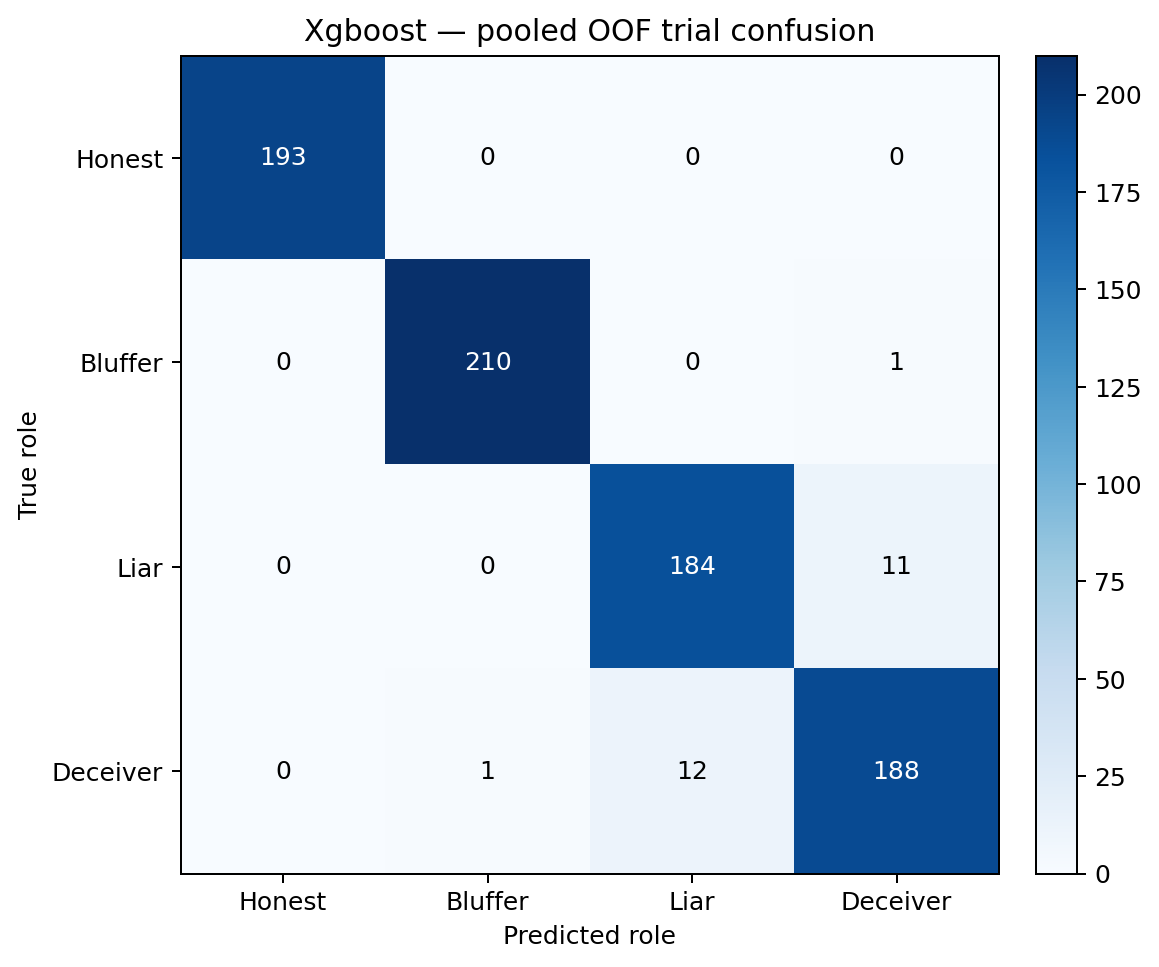

In [7]:
confusion_path = RESULT_DIR / f"confusion_matrix_{best_model}.png"
if not show_existing_figure(confusion_path, width=720):
    stored_trials = results["oof_trial_predictions"]
    model_trials = stored_trials.loc[stored_trials["model"] == best_model]
    if {"true_role", "predicted_role"}.issubset(model_trials.columns) and not model_trials.empty:
        display(Markdown("> The image below was reconstructed only for display from the stored out-of-fold trial predictions; no model was rerun."))
        confusion_display = pd.crosstab(model_trials["true_role"], model_trials["predicted_role"]).reindex(
            index=CLASS_ORDER, columns=CLASS_ORDER, fill_value=0
        )
        fig, ax = plt.subplots(figsize=(6.2, 5.2))
        image = ax.imshow(confusion_display.to_numpy(), cmap="Blues")
        for row in range(len(CLASS_ORDER)):
            for column in range(len(CLASS_ORDER)):
                ax.text(column, row, int(confusion_display.iloc[row, column]), ha="center", va="center")
        ax.set(xticks=range(4), yticks=range(4), xticklabels=CLASS_ORDER, yticklabels=CLASS_ORDER,
               xlabel="Predicted class", ylabel="True class", title=f"{best_model_name}: pooled trial confusion matrix")
        plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
        fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
        fig.tight_layout()
        plt.show()
        FIGURES_DISPLAYED += 1
    else:
        display(Markdown("> Stored out-of-fold trial labels are unavailable, so the missing image cannot be reconstructed."))

# 8. Fold-Level Performance

Fold-level metrics below are filtered from the stored `fold_metrics.csv` rows for the best model.

,Fold,Trial Accuracy,Trial Macro F1,Trial Weighted F1,Cohen's Kappa,Test Trials,Overlapping Participants
0,1,0.9750,0.9749,0.9750,0.9663,80,46
1,2,0.9875,0.9874,0.9875,0.9833,80,44
2,3,1.0000,1.0000,1.0000,1.0000,80,45
3,4,0.9250,0.9205,0.9257,0.8995,80,46
4,5,0.9500,0.9499,0.9501,0.9329,80,47
5,6,0.9625,0.9593,0.9624,0.9499,80,45
6,7,0.9750,0.9750,0.9750,0.9667,80,45
7,8,0.9625,0.9606,0.9623,0.9497,80,45
8,9,0.9625,0.9625,0.9625,0.9500,80,44
9,10,0.9875,0.9881,0.9875,0.9833,80,45


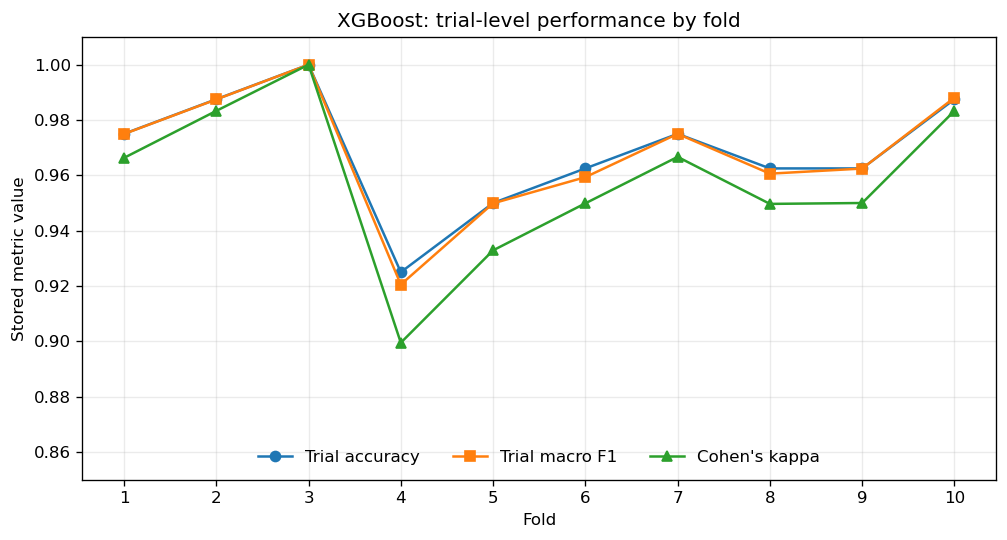

In [8]:
fold_metrics_all = results["fold_metrics"]
best_folds_raw = fold_metrics_all.loc[fold_metrics_all["model"] == best_model].sort_values("fold").copy()
fold_columns = {
    "fold": "Fold",
    "trial_accuracy": "Trial Accuracy",
    "trial_macro_f1": "Trial Macro F1",
    "trial_weighted_f1": "Trial Weighted F1",
    "trial_cohen_kappa": "Cohen's Kappa",
    "n_test_trials": "Test Trials",
    "n_overlapping_participants": "Overlapping Participants",
}
best_fold_table = best_folds_raw.loc[:, list(fold_columns)].rename(columns=fold_columns)
show_table(best_fold_table.reset_index(drop=True))

fold_figure_candidates = sorted(RESULT_DIR.glob("*fold*performance*.png"))
if fold_figure_candidates:
    _ = show_existing_figure(fold_figure_candidates[0], width=850)
else:
    fig, ax = plt.subplots(figsize=(8.5, 4.6))
    ax.plot(best_folds_raw["fold"], best_folds_raw["trial_accuracy"], marker="o", label="Trial accuracy")
    ax.plot(best_folds_raw["fold"], best_folds_raw["trial_macro_f1"], marker="s", label="Trial macro F1")
    ax.plot(best_folds_raw["fold"], best_folds_raw["trial_cohen_kappa"], marker="^", label="Cohen's kappa")
    ax.set(xlabel="Fold", ylabel="Stored metric value", title=f"{best_model_name}: trial-level performance by fold",
           xticks=best_folds_raw["fold"].tolist(), ylim=(0.85, 1.01))
    ax.legend(frameon=False, ncol=3, loc="lower center")
    fig.tight_layout()
    plt.show()
    FIGURES_DISPLAYED += 1

# 9. Pooled Versus Mean-Across-Folds Results

**Pooled out-of-fold metrics** are calculated after combining all trial predictions from all 10 test folds, giving equal weight to each trial. **Mean-across-fold metrics** are calculated within each fold and then averaged, giving equal weight to each fold. Small differences can arise even when every fold has the same nominal number of test trials because nonlinear metrics depend on each fold's class composition.

In [9]:
pooled_vs_folds = pd.DataFrame(
    [
        ("Accuracy", best_row["pooled_trial_accuracy"], best_row["trial_fold_accuracy_mean"], best_row["trial_fold_accuracy_std"]),
        ("Macro F1", best_row["pooled_trial_macro_f1"], best_row["trial_fold_macro_f1_mean"], best_row["trial_fold_macro_f1_std"]),
        ("Weighted F1", best_row["pooled_trial_weighted_f1"], best_row["trial_fold_weighted_f1_mean"], best_row["trial_fold_weighted_f1_std"]),
        ("Cohen's Kappa", best_row["pooled_trial_cohen_kappa"], best_row["trial_fold_cohen_kappa_mean"], best_row["trial_fold_cohen_kappa_std"]),
    ],
    columns=["Metric", "Pooled OOF", "Fold Mean", "Fold SD"],
)
show_table(pooled_vs_folds)

,Metric,Pooled OOF,Fold Mean,Fold SD
0,Accuracy,0.9688,0.9688,0.0214
1,Macro F1,0.9685,0.9678,0.0227
2,Weighted F1,0.9687,0.9688,0.0213
3,Cohen's Kappa,0.9583,0.9582,0.0288


# 10. Participant Overlap

> **This evaluation is trial-grouped but not subject-independent. Participants may occur in both the training and test portions of a fold. Therefore, these results represent within-dataset discrimination rather than generalization to unseen subjects.**

In [10]:
overlap_table = overlap[[
    "fold", "n_train_participants", "n_test_participants", "n_overlapping_participants",
    "participant_overlap_fraction_of_test", "trial_overlap_count",
]].copy()
overlap_table["participant_overlap_fraction_of_test"] *= 100
overlap_table = overlap_table.rename(
    columns={
        "fold": "Fold",
        "n_train_participants": "Training Participants",
        "n_test_participants": "Testing Participants",
        "n_overlapping_participants": "Overlapping Participants",
        "participant_overlap_fraction_of_test": "Test-Participant Overlap (%)",
        "trial_overlap_count": "Overlapping Trials",
    }
)
show_table(overlap_table.reset_index(drop=True))

,Fold,Training Participants,Testing Participants,Overlapping Participants,Test-Participant Overlap (%),Overlapping Trials
0,1,48,46,46,100.0000,0
1,2,48,44,44,100.0000,0
2,3,48,45,45,100.0000,0
3,4,48,46,46,100.0000,0
4,5,48,47,47,100.0000,0
5,6,48,45,45,100.0000,0
6,7,48,45,45,100.0000,0
7,8,48,45,45,100.0000,0
8,9,48,44,44,100.0000,0
9,10,48,45,45,100.0000,0


# 11. Existing Model Comparison Figure

The stored model-comparison figure is embedded without regeneration.

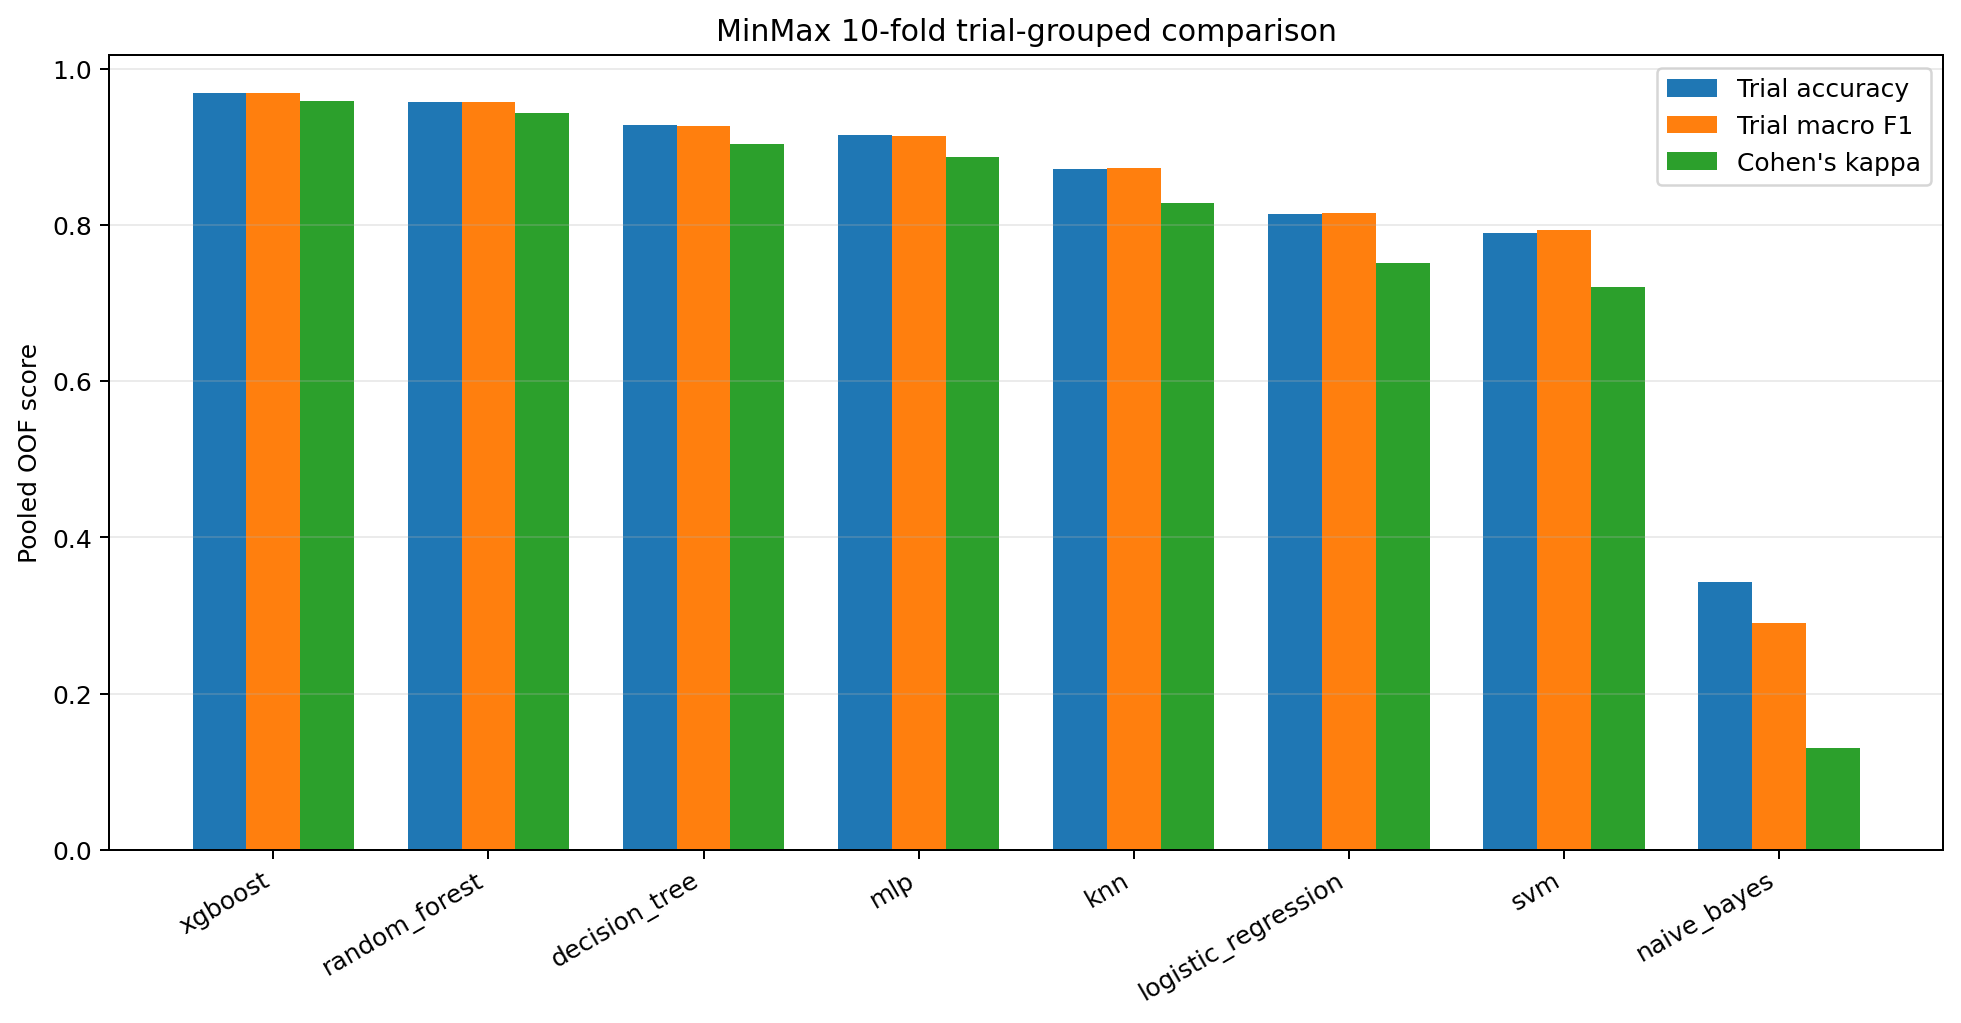

In [11]:
_ = show_existing_figure(RESULT_DIR / "model_comparison.png", width=1000)

# 12. Conference-Ready Results Tables

The following compact tables use the stored trial-level metrics and are formatted for direct adaptation to an IEEE conference paper.

### Table A. Overall model comparison

In [12]:
table_a = comparison[[
    "model", "pooled_trial_accuracy", "pooled_trial_macro_f1",
    "pooled_trial_weighted_f1", "pooled_trial_cohen_kappa",
]].rename(
    columns={
        "model": "Model",
        "pooled_trial_accuracy": "Accuracy",
        "pooled_trial_macro_f1": "Macro F1",
        "pooled_trial_weighted_f1": "Weighted F1",
        "pooled_trial_cohen_kappa": "Cohen's Kappa",
    }
)
table_a["Model"] = table_a["Model"].map(lambda name: MODEL_DISPLAY.get(name, name))
table_a = table_a.sort_values("Macro F1", ascending=False).reset_index(drop=True)
show_table(table_a, highlight_first_row=True)

Model,Accuracy,Macro F1,Weighted F1,Cohen's Kappa
XGBoost,0.9688,0.9685,0.9687,0.9583
Random Forest,0.9575,0.9571,0.9575,0.9433
Decision Tree,0.9275,0.9272,0.9277,0.9033
MLP,0.9150,0.9141,0.9147,0.8866
KNN,0.8712,0.8723,0.8728,0.8282
Logistic Regression,0.8138,0.8155,0.8160,0.7517
SVM,0.7900,0.7931,0.7935,0.7200
Gaussian Naive Bayes,0.3425,0.2910,0.2900,0.1305


### Table B. Per-class performance of the best model

In [13]:
table_b = best_per_class[["Class", "Precision", "Recall", "F1-score"]].reset_index(drop=True)
show_table(table_b)

,Class,Precision,Recall,F1-score
0,Honest,1.0000,1.0000,1.0000
1,Bluffer,0.9953,0.9953,0.9953
2,Liar,0.9388,0.9436,0.9412
3,Deceiver,0.9400,0.9353,0.9377


### Table C. Cross-validation stability of the best model

In [14]:
table_c = pooled_vs_folds[["Metric", "Fold Mean", "Fold SD"]].rename(
    columns={"Fold Mean": "Mean", "Fold SD": "Standard Deviation"}
)
show_table(table_c)

,Metric,Mean,Standard Deviation
0,Accuracy,0.9688,0.0214
1,Macro F1,0.9678,0.0227
2,Weighted F1,0.9688,0.0213
3,Cohen's Kappa,0.9582,0.0288


# 13. Conference-Ready Results Paragraph

Eight machine-learning classifiers were evaluated using trial-grouped 10-fold cross-validation with MinMax normalization. All windows originating from the same EEG trial were assigned to the same fold. The best-performing classifier was XGBoost, which achieved a pooled trial-level accuracy of 0.9688, a macro F1-score of 0.9685, a weighted F1-score of 0.9687, and a Cohen's kappa coefficient of 0.9583. Across the 10 folds, the model obtained a mean macro F1-score of 0.9678 ± 0.0227. The confusion matrix indicated that Honest was classified most reliably, while the greatest confusion occurred between Liar and Deceiver (23 bidirectional errors). Since participants were permitted to appear across folds, the reported results represent within-dataset classification performance rather than generalization to unseen subjects.

*The class-reliability statement is supported by the stored per-class trial F1-scores; the confusion statement is supported by the stored best-model confusion matrix and out-of-fold trial predictions.*

# 14. Limitations

- The evaluation is not subject-independent; participant overlap between training and test portions may increase measured performance.
- Overlapping windows from a trial are correlated, although trial grouping prevented those windows from crossing fold boundaries.
- The results should not be interpreted as evidence of generalization to unseen participants.
- The findings apply to this controlled mock-crime protocol and should not be generalized beyond that setting without further validation.

# XGBoost Explainability Using SHAP

SHAP values were calculated only for the **out-of-fold test windows** from the stored non-subject-wise MinMax 10-fold experiment. Each window was explained by the saved XGBoost model from the fold in which that window's trial was held out. The fitted fold-specific median imputer and MinMax scaler were reused without refitting.

Mean absolute SHAP values measure contribution magnitude. The global bar plot averages magnitudes across all explained windows and all four classes; the heatmap retains separate Honest, Bluffer, Liar, and Deceiver magnitudes. Because participants can occur in both training and test portions, this analysis is trial-grouped but **not subject-independent**.

> SHAP importance indicates model reliance. It is not causality, does not prove that a brain region generates deception, and does not show whether a feature increases or decreases a class output.


## Top-20 out-of-fold SHAP importance table

The same globally selected features and ordering are used in both figures.

In [15]:
SHAP_DIR = RESULT_DIR / "shap"
SHAP_TOP20_PATH = SHAP_DIR / "xgboost_top20_shap.csv"
SHAP_MAPPING_PATH = SHAP_DIR / "feature_name_mapping.csv"
required_shap_files = [
    SHAP_TOP20_PATH,
    SHAP_MAPPING_PATH,
    SHAP_DIR / "xgboost_global_top20_shap.png",
    SHAP_DIR / "xgboost_classwise_top20_shap_heatmap.png",
]
missing_shap_files = [path.as_posix() for path in required_shap_files if not path.is_file()]
if missing_shap_files:
    raise FileNotFoundError(f"Missing SHAP presentation files: {missing_shap_files}")

shap_top20 = pd.read_csv(SHAP_TOP20_PATH)
shap_mapping = pd.read_csv(SHAP_MAPPING_PATH)
display_name_by_feature = shap_mapping.set_index("feature")["display_feature"].to_dict()
shap_table = shap_top20.copy()
shap_table["feature"] = shap_table["feature"].map(display_name_by_feature)
shap_table = shap_table.rename(
    columns={
        "rank": "Rank",
        "feature": "EEG Feature",
        "global_mean_abs_shap": "Global mean |SHAP|",
        "honest_mean_abs_shap": "Honest mean |SHAP|",
        "bluffer_mean_abs_shap": "Bluffer mean |SHAP|",
        "liar_mean_abs_shap": "Liar mean |SHAP|",
        "deceiver_mean_abs_shap": "Deceiver mean |SHAP|",
    }
)
show_table(shap_table)


,Rank,EEG Feature,Global mean |SHAP|,Honest mean |SHAP|,Bluffer mean |SHAP|,Liar mean |SHAP|,Deceiver mean |SHAP|
0,1,T8 – Waveform length,0.2423,0.2328,0.3840,0.1568,0.1958
1,2,O2 – Waveform length,0.2311,0.1898,0.2921,0.3469,0.0957
2,3,Cz – Waveform length,0.2267,0.0881,0.4198,0.0992,0.2998
3,4,P4 – Waveform length,0.2086,0.2687,0.2703,0.1085,0.1867
4,5,C4 – Waveform length,0.2000,0.0572,0.4194,0.1854,0.1381
5,6,F3 – Waveform length,0.1863,0.3319,0.0657,0.2711,0.0764
6,7,T7 – Waveform length,0.1686,0.2632,0.0289,0.3304,0.0518
7,8,Fz – Waveform length,0.1680,0.2744,0.2154,0.0513,0.1311
8,9,C3 – Waveform length,0.1614,0.2743,0.0563,0.1712,0.1438
9,10,F4 – Waveform length,0.1485,0.3450,0.1495,0.0504,0.0490


## Global top-20 SHAP importance

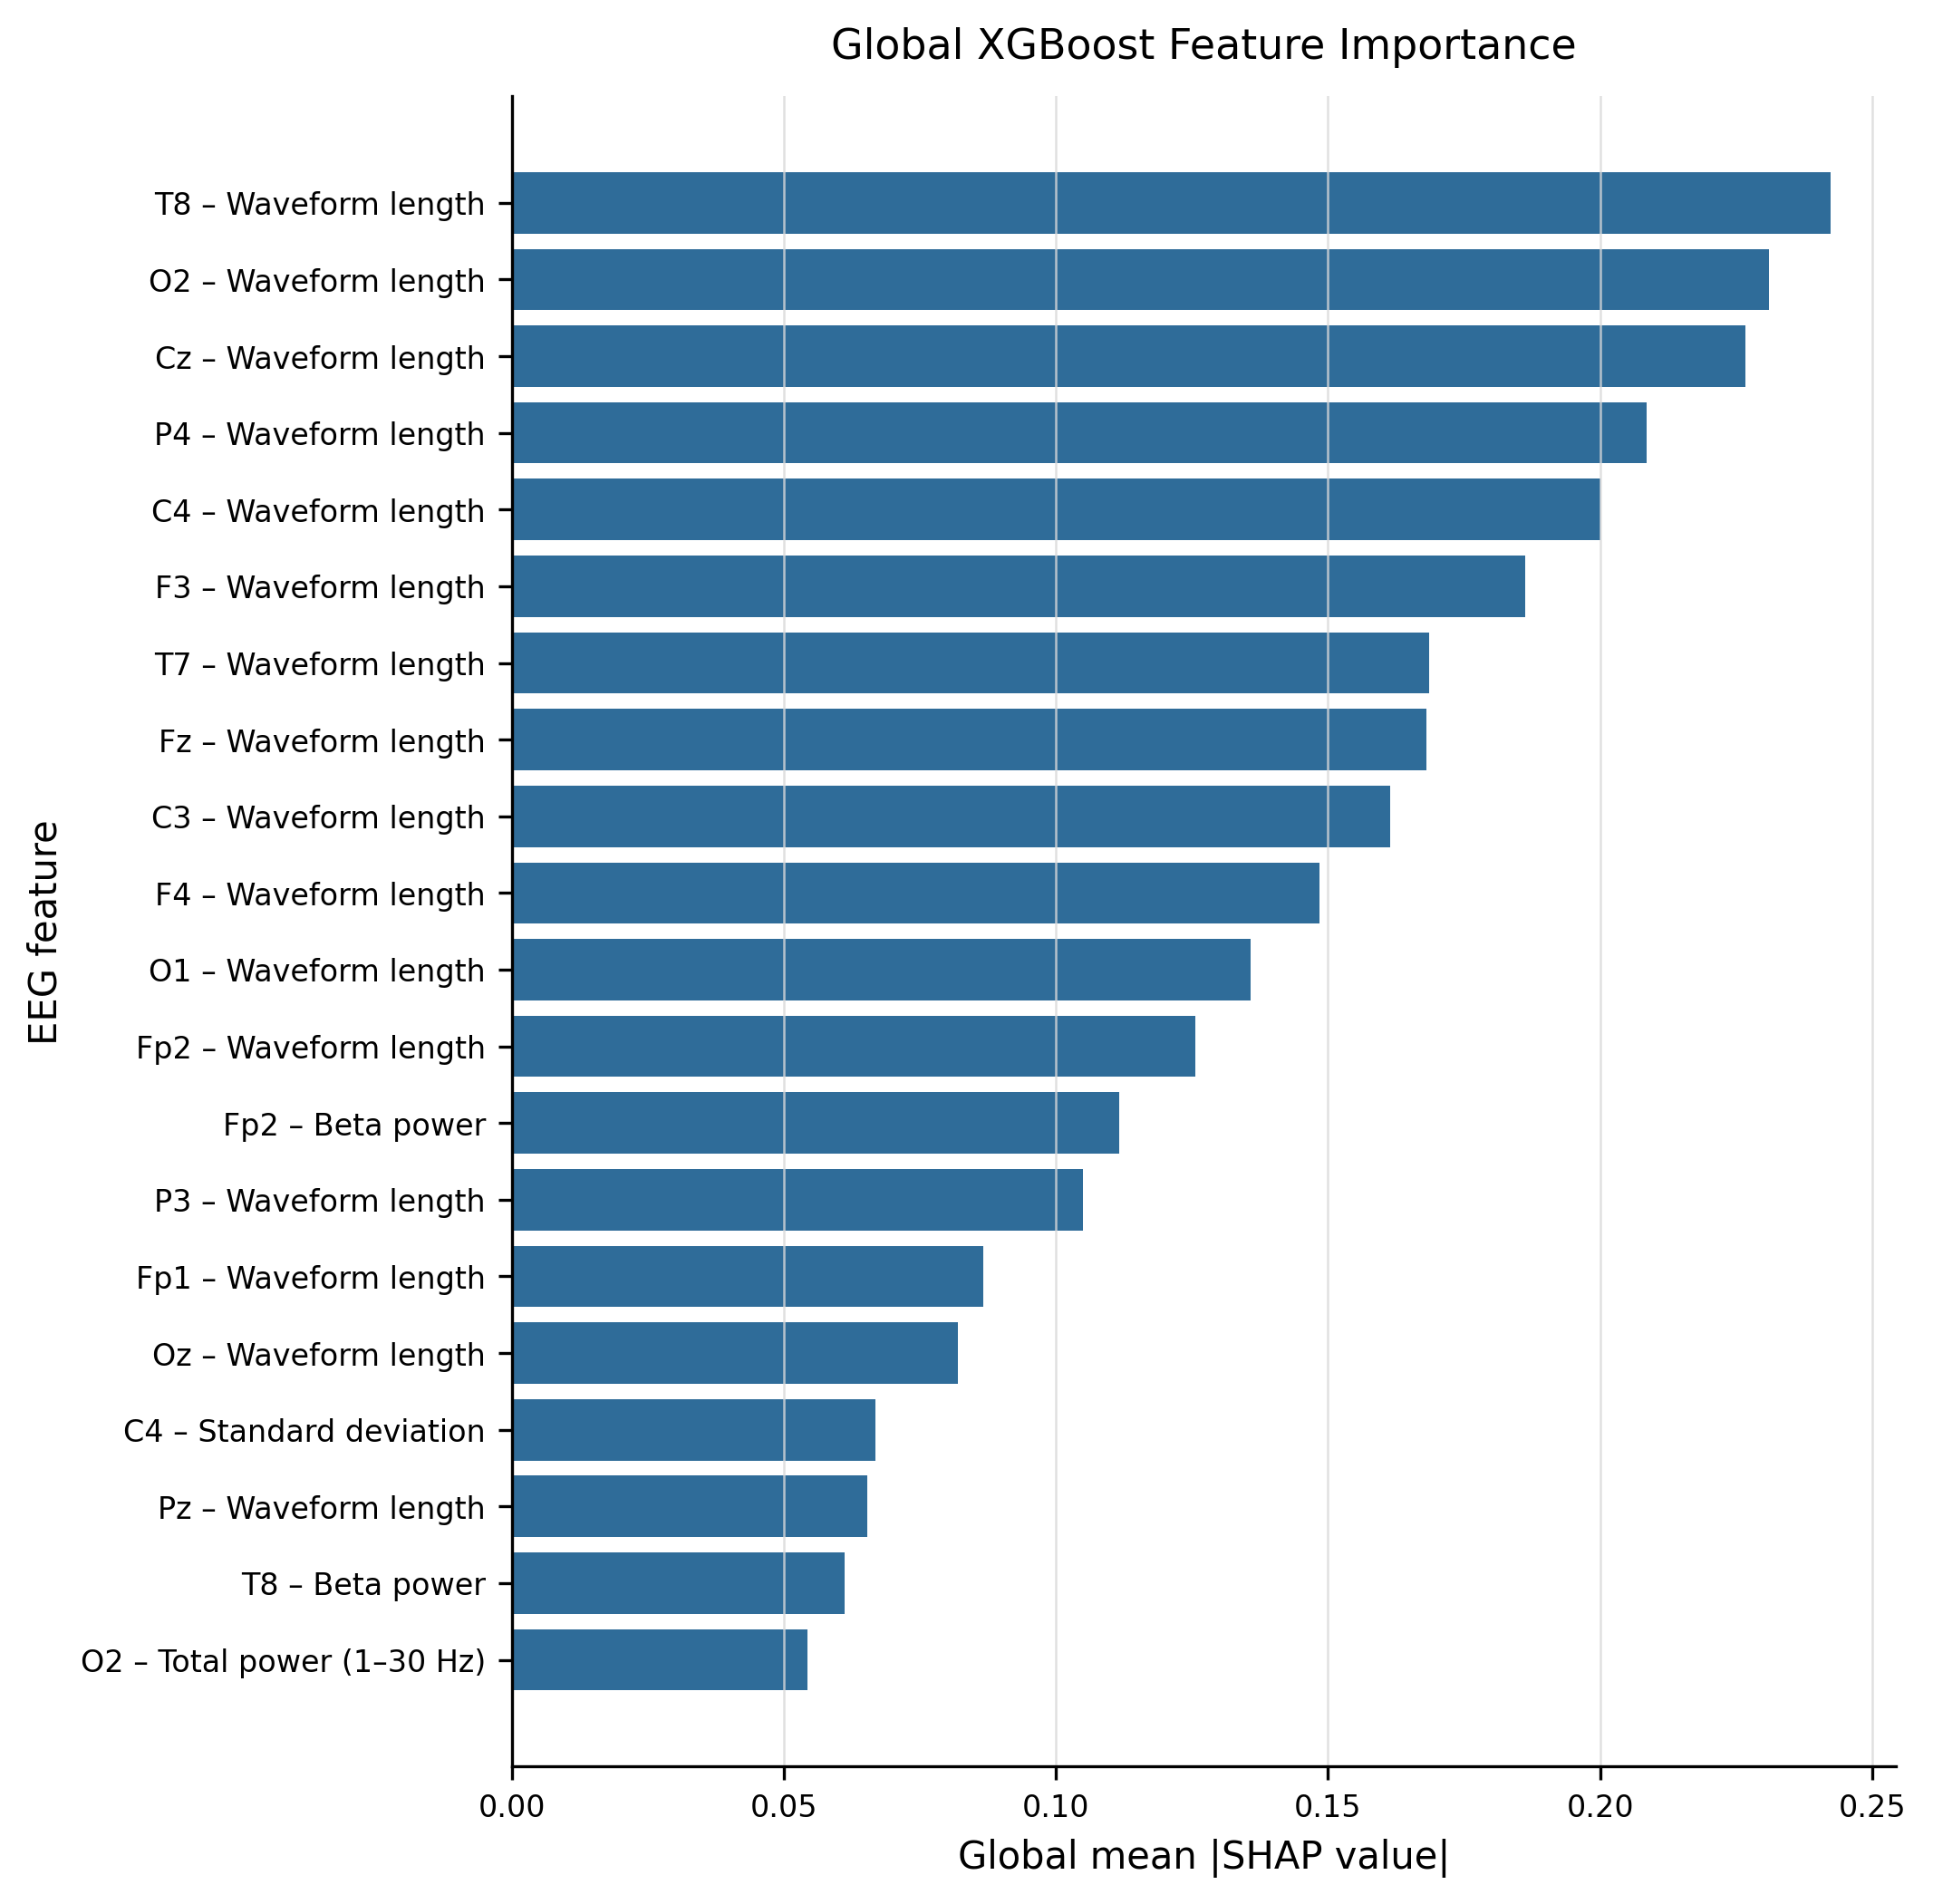

In [16]:
_ = show_existing_figure(
    SHAP_DIR / "xgboost_global_top20_shap.png",
    width=900,
)


*Global mean absolute SHAP importance of the 20 most influential EEG features for the XGBoost classifier. Importance values were aggregated across the four behavioral classes using out-of-fold test-window explanations.*

## Class-wise SHAP heatmap

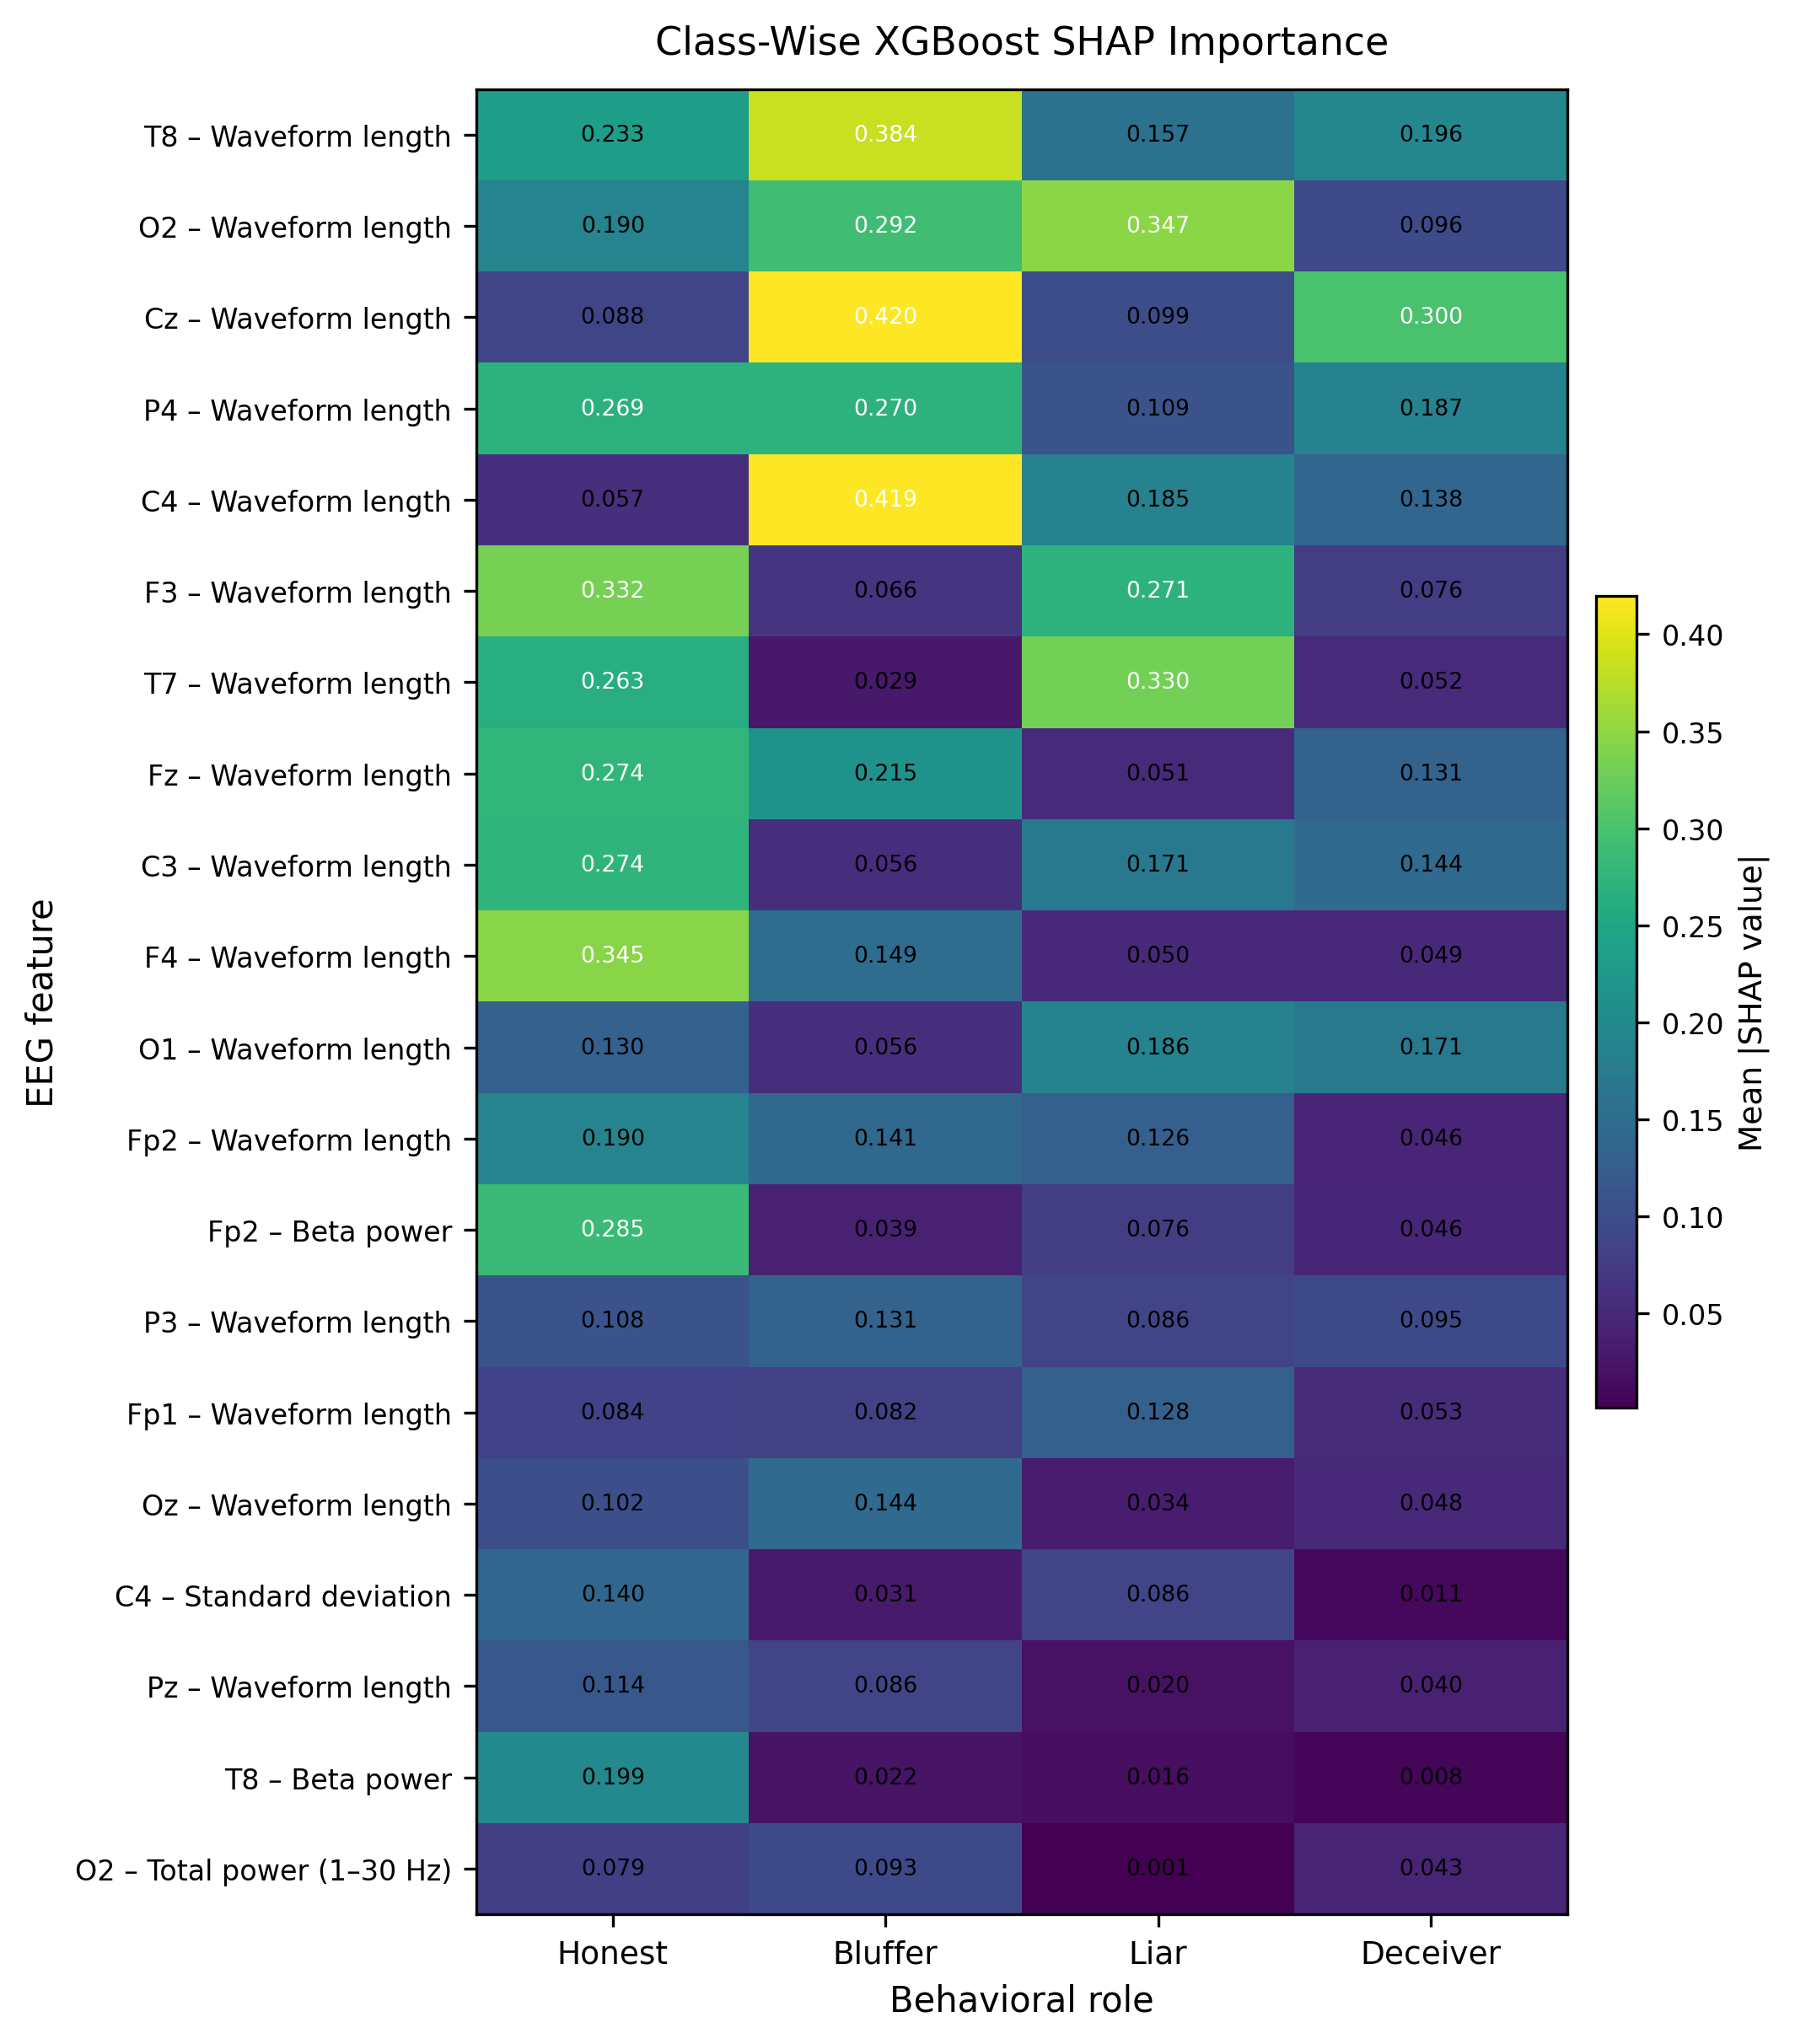

In [17]:
_ = show_existing_figure(
    SHAP_DIR / "xgboost_classwise_top20_shap_heatmap.png",
    width=900,
)


*Class-wise mean absolute SHAP importance for the 20 globally most influential EEG features. Each column represents one behavioral role, and larger values indicate a stronger contribution of the feature to the corresponding XGBoost class output. SHAP values were computed using out-of-fold test windows.*

### Concise interpretation

The three most globally important features were:

1. **T8 – Waveform length** (`f__T8__waveform_length`): global mean |SHAP value| = 0.242331; the largest class-specific magnitude was for **Bluffer** (0.383972).
2. **O2 – Waveform length** (`f__O2__waveform_length`): global mean |SHAP value| = 0.231117; the largest class-specific magnitude was for **Liar** (0.346865).
3. **Cz – Waveform length** (`f__Cz__waveform_length`): global mean |SHAP value| = 0.226731; the largest class-specific magnitude was for **Bluffer** (0.419836).

The three leading features are not concentrated in one channel; they span T8, O2, Cz.
The three leading features are not concentrated in one electrode-region label; they span temporal, occipital, central.
All three leading features are concentrated in the time-domain feature family.

These magnitudes describe which inputs the fitted classifier relied on. They do not show direction of effect, physiological causality, or proof that a brain region generates deception.

## Notebook Execution Summary

In [18]:
print(f"Notebook path: {NOTEBOOK_PATH.as_posix()}")
print(f"Result directory used: {RESULT_DIR.as_posix()}")
print(f"Best model identified: {best_model_name}")
print(f"Tables displayed: {TABLES_DISPLAYED}")
print(f"Figures displayed: {FIGURES_DISPLAYED}")
print("Missing files: " + (", ".join(missing_files) if missing_files else "None"))
print("Experiment rerun: No — this notebook loaded stored results and created presentation-only summaries.")

Notebook path: EEG Deception Results.ipynb
Result directory used: outputs/minmax_10fold_trial_grouped
Best model identified: XGBoost
Tables displayed: 13
Figures displayed: 5
Missing files: None
Experiment rerun: No — this notebook loaded stored results and created presentation-only summaries.
